# DFG benchmark 2D-3 (Re = 100, fixed time interval) — RBF-FD

Adapted from the 2D-2 (periodic) notebook. Reference: [Featflow DFG 2D-3](https://wwwold.mathematik.tu-dortmund.de/~featflow/en/benchmarks/cfdbenchmarking/flow/dfg_benchmark3_re100.html)

**What changed with respect to 2D-2** (geometry, mesh, RBF operators, boundary sets and the projection scheme are untouched):

| | 2D-2 | 2D-3 |
|---|---|---|
| Inflow | $U_{max}=1.5$ constant (with a short start-up ramp) | $U(t) = 1.5\,\sin(\pi t_{dim}/8)$, evaluated at $t_{n+1}$ every step |
| Initial condition | $u=0$ | $u=0$ at $t=0$ (same) |
| Time interval | until periodic | exactly $t_{dim}\in[0,8]$ |
| Time step | $5\cdot10^{-3}$ (non-dim.) | $k = 1/1600$ (dimensional) |
| Outputs | min / max / mean / amp of $C_D, C_L$, Strouhal | $C_D(t), C_L(t), \Delta p(t)$; $\max C_D$, $\max C_L$ and their times; $\Delta p(t=8)$ |
| Steady-state stop | yes | removed (the run always goes to $t=8$) |

**Units.** The mesh is non-dimensional (lengths scaled by $D_{dim}=0.1$, velocities by $\bar U=1$), so
$t = t_{dim}\,\bar U/D_{dim} = 10\,t_{dim}$. Then $[0,8]\to[0,80]$ and $k=1/1600 \to \Delta t = 1/160 = 0.00625$ (12 800 steps).
Pressure and force coefficients are unchanged by this scaling ($\rho=1$, $\bar U=1$). The probe points
$a_1=(0.15,0.2)$, $a_2=(0.25,0.2)$ become $(1.5,2)$ and $(2.5,2)$. All results are reported in **dimensional time** for comparison with the tables.

The coefficients always use the fixed $\bar U = 1$ (not the instantaneous inflow), as in the benchmark.


In [1]:
from scipy.io import loadmat
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import cKDTree
from scipy.linalg import solve
from scipy.optimize import least_squares
from scipy.spatial.distance import pdist
from scipy.sparse import lil_matrix, csc_matrix
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import splu
import scipy as sp


In [73]:
mesh = loadmat("mesh_claude_h0_02.mat")
L = 22
AR = L
H = 4.1
Re = 100   
h0 = 0.04
R = 0.5
xc = 2
yc = 2

nodes = mesh["pressure"]
triangles = mesh["t"] - 1       # MATLAB -> Python indexing
pressure = mesh["p"] 


tree = cKDTree(nodes)
d, _ = tree.query(nodes, k=2)          # k=2: self (dist 0) + nearest neighbor
nn_dist = d[:, 1]
print("mean:", nn_dist.mean(), "min:", nn_dist.min())







mean: 0.07346028930449441 min: 0.009689426947276113


In [74]:
#Velocity nodes classification
nodes_u = nodes.copy()

boundary_inlet = np.where(
    (np.abs(nodes_u[:,0] - nodes_u[:,0].min() )< 1e-12) & (nodes_u[:,1] > nodes_u[:,1].min() + 1e-12 ) & (nodes_u[:,1] < nodes_u[:,1].max())
)[0]

boundary_outlet = np.where(
    (np.abs(nodes_u[:,0] - nodes_u[:,0].max()) < 1e-12)  & (nodes_u[:,1] > 0) & (nodes_u[:,1] < H)
)[0]
boundary_walls_up = np.where(
    
    (np.abs(nodes_u[:,1] - H )<= 1e-8) 
)[0]
boundary_walls_down = np.where(
    (np.abs(nodes_u[:,1]) < 1e-6 )
)[0]
boundary_obstacle = np.where((((nodes_u[:,0]-xc)**2+(nodes_u[:,1]-yc)**2) <= R**2) & (nodes_u[:,1]>0))[0]
border_nodes = np.concatenate((boundary_inlet
                               ,boundary_outlet
                               ,boundary_walls_down,boundary_walls_up,boundary_obstacle))
mask = np.ones(len(nodes_u), dtype=bool)
mask[border_nodes] = False
interior_nd = np.where(mask)[0]
nodes_u.shape

(10766, 2)

In [75]:
#Pressure nodes classification
centers_p = pressure.copy()

p_wall_up = np.where((np.abs(centers_p[:,1] - H)<= 1e-9))[0]
p_wall_down = np.where(np.abs(centers_p[:,1])<= 1e-10)[0]
p_inlet = np.where((np.abs(centers_p[:,0]- centers_p[:,0].min())<=1e-12) & (centers_p[:,1] < H) & (centers_p[:,1] > centers_p[p_wall_down][0,1]))[0]
p_outlet = np.where((np.abs(centers_p[:,0]-centers_p[:,0].max())<=1e-12) & (centers_p[:,1] < H) & (centers_p[:,1] > centers_p[p_wall_down][0,1]))[0]
p_obstacle = np.where((((centers_p[:,0]-xc)**2+(centers_p[:,1]-yc)**2 -R**2)<=h0/10000) & (centers_p[:,1]>=h0/10000))[0]
mask = np.ones(len(centers_p), dtype=bool)
mask[ np.concatenate((p_obstacle,
                      p_wall_up,p_wall_down
                      ,p_inlet,p_outlet
                      ))
      
                     ] = False



p_interior = np.where(mask)[0]
centers_p.shape

(3718, 2)

In [76]:
p_obstacle

array([ 419,  421,  422,  424,  425,  427,  428,  436,  437,  443,  444,
        451,  452,  458,  459,  468,  469,  480,  481,  490,  491,  501,
        502,  511,  512,  523,  524,  537,  538,  550,  551,  562,  563,
        579,  580,  588,  589,  600,  601,  621,  622,  636,  637,  646,
        647,  663,  664,  674,  675,  692,  693,  707,  708,  721,  722,
        737,  738,  754,  755,  769,  770,  783,  784,  800,  801,  812,
        813,  829,  830,  845,  846,  862,  863,  875,  876,  889,  890,
        907,  908,  923,  924,  936,  937,  949,  950,  964,  965,  978,
        979,  993,  994, 1005, 1006, 1016, 1017, 1036, 1037, 1046, 1047,
       1059, 1060, 1070, 1071, 1083, 1084, 1091, 1092, 1101, 1102, 1115,
       1116, 1124, 1125, 1133, 1134, 1141, 1142, 1147, 1148, 1155, 1156,
       1159, 1160, 1162, 1163, 1164])

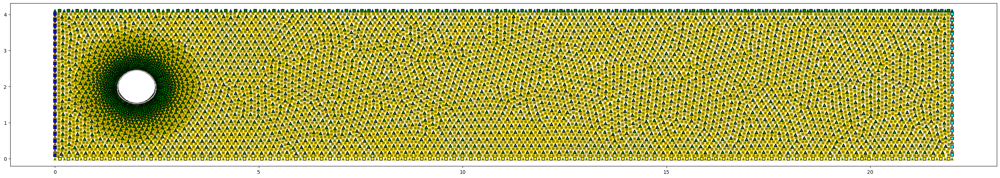

In [77]:
plt.figure(figsize=(36,6))
plt.scatter(nodes_u[:,0], nodes_u[:,1],
            marker = "s", color='red',edgecolor = "black")

plt.scatter(nodes_u[boundary_inlet][:,0], nodes_u[boundary_inlet][:,1],
            marker = "s", color='blue',edgecolor = "black")
plt.scatter(nodes_u[boundary_outlet][:,0], nodes_u[boundary_outlet][:,1],
            marker = "s", color='cyan',edgecolor = "black")

plt.scatter(nodes_u[interior_nd][:,0], nodes_u[interior_nd][:,1],
            marker = "s", color='olive',edgecolor = "gold")


plt.scatter(nodes_u[boundary_walls_up][:,0], nodes_u[boundary_walls_up][:,1],
            marker = "s", color='green',edgecolor = "black")
plt.scatter(nodes_u[boundary_walls_down][:,0], nodes_u[boundary_walls_down][:,1],
            marker = "s", color='yellow',edgecolor = "black")
plt.scatter(nodes_u[boundary_obstacle][:,0], nodes_u[boundary_obstacle][:,1],
            marker = "s", color='gold',edgecolor = "black")


plt.scatter(centers_p[:,0], centers_p[:,1],
            marker = "^", color='white',edgecolor = "black")
plt.scatter(centers_p[p_inlet][:,0], centers_p[p_inlet][:,1],
            marker = "^", color='orange',edgecolor = "black")
plt.scatter(centers_p[p_outlet][:,0], centers_p[p_outlet][:,1],
            marker = "^", color='orange',edgecolor = "black")

plt.scatter(centers_p[p_wall_down][:,0], centers_p[p_wall_down][:,1],
            marker = "^", color='green',edgecolor = "gold")
plt.scatter(centers_p[p_wall_up][:,0], centers_p[p_wall_up][:,1],
            marker = "^", color='blue',edgecolor = "green")
plt.scatter(centers_p[p_obstacle][:,0], centers_p[p_obstacle][:,1],
            marker = "^", color='pink',edgecolor = "silver")
plt.scatter(centers_p[p_interior][:,0], centers_p[p_interior][:,1],
            marker = "^", color='green',edgecolor = "black")


In [78]:
nodes_u.shape

(10766, 2)

In [79]:
N_u = nodes_u.shape[0]
N_p = centers_p.shape[0]
# --------------------------------------------------
# 3. RBF definition (PHS r^3)
# --------------------------------------------------
#Types: MQ: Multicuadrics, even_TPS,odd_TPS, Gaussian
Type = 'odd_TPS'

if Type == 'even_TPS':
    a = 3
    print("TPS")
    def phi(r):
        result = np.zeros_like(r)
        result[r != 0] = r[r!= 0]**(2*a) * np.log(r[r!= 0])
        return result#r**(2*a)#
    def laplacian_phi(r):
        # Laplacian of r^(2*a) in 2D: Δ(r^(2*a)) = 4*a*(2*a-2)*r^(2*a-4)
        result = np.zeros_like(r)
        result[r != 0] = 4*a*r[r!= 0]**(2*a-2)*(a*np.log(r[r!=0]) + 1)
        return result# 4*a**2*r**(2*a-2)#
    def phi_dx(r,x,xc):
        result = np.zeros_like(r)
        result[r!=0] = r[r!=0]**(2*a-2)*(2*a*np.log(r[r!=0]) + 1)*(x-xc)[r!=0]
        return result#2*a*r**(2*a-2)*(x-xc)#
    def phi_dy(r,y,yc):
        result = np.zeros_like(r)
        result[r!=0] = r[r!=0]**(2*a-2)*(2*a*np.log(r[r!=0]) + 1)*(y-yc)[r!=0]
        return result#2*a*r**(2*a-2)*(y-yc)#
    def phi_dx2(r,x,xc):
        result= np.zeros_like(r)
        result[r!=0] = (r[r!=0]**(2*a-2)*(2*a*np.log(r[r!=0]) + 1) + r[r!=0]**(2*a-4)*((2*a-2)*(2*a*np.log(r[r!=0]) + 1) +2*a))*(x - xc)[r!=0]**2
        return result#2*a*(r**(2*a-2) + (x-xc)**2 * (2*a-2)*r**(2*a-4))#   
    def phi_dy2(r,y,yc):
        result= np.zeros_like(r)
        result[r!=0] = (r[r!=0]**(2*a-2)*(2*a*np.log(r[r!=0]) + 1) + r[r!=0]**(2*a-4)*((2*a-2)*(2*a*np.log(r[r!=0]) + 1) +2*a))*(y - yc)[r!=0]**2
        return result#2*a*(r**(2*a-2) + (y-yc)**2 * (2*a-2)*r**(2*a-4))# 
elif Type == 'odd_TPS':
    a = 7
    def phi(r):
        return r**(a)
    def laplacian_phi(r):
        return  a**2*r**(a-2)#
    def phi_dx(r,x,xc):
        return a*r**(a-2)*(x-xc)#
    def phi_dy(r,y,yc):
        return a*r**(a-2)*(y-yc)#
    def phi_dx2(r,x,xc):
        return a*(r**(a-2) + (x-xc)**2 * (a-2)*r**(a-4))#   
    def phi_dy2(r,y,yc):
        return a*(r**(a-2) + (y-yc)**2 * (a-2)*r**(a-4))# 

elif Type == 'Gaussian':
    print("Gaussian")
    eps = 8.133652754717849 #0.3*( np.abs(x_nd[1]-x_nd[0])**2 + np.abs(y_nd[1]-y_nd[0])**2)**0.5# 0.32/( np.abs(x_nd[1]-x_nd[0]) + np.abs(y_nd[1]-y_nd[0]))/2 #1.5#5.0
    def phi(r):
        return np.exp(-(eps*r)**2)
    def laplacian_phi(r):
        return 4*eps**2*(eps**2*r**2 - 1)*np.exp(-(eps*r)**2)
    def phi_dx(r,x,xc):
        return -2*eps**2*np.exp(-eps**2*r**2)*(x-xc)
    def phi_dx2(r,x,xc):
        return -2*eps**2*(-2*eps**2*np.exp(-eps**2*r**2)*(x-xc)**2 +  np.exp(-eps**2*r**2))
    def phi_dy2(r,y,yc):
        return -2*eps**2*(-2*eps**2*np.exp(-eps**2*r**2)*(y-yc)**2 +  np.exp(-eps**2*r**2))
    def phi_dy(r,y,yc):
        return -2*eps**2*np.exp(-eps**2*r**2)*(y-yc)
elif Type == 'MQ':
    print("Multiquadrics")
    eps = 0.5*min_dist_v
    def phi(r):
        return np.sqrt(r**2 + eps**2)
    def phi_dx(r,x,xc):
        return (x-xc)/(np.sqrt(r**2 + eps**2))
    def phi_dy(r,y,yc):
        return (y-yc)/(np.sqrt(r**2 + eps**2))
    def phi_dx2(r,x,xc):
        return (r**2-(x-xc)**2 +eps**2)/(r**2+eps**2)**(3/2)
    def phi_dy2(r,y,yc):
        return (r**2-(y-yc)**2 +eps**2)/(r**2+eps**2)**(3/2)
    def laplacian_phi(r):
        return (r**2 + 2*eps**2)/(r**2+eps**2)**(3/2)

In [80]:
if Type == 'Gaussian':
        print('Gauss')
        stencil_size = 19
elif Type == 'odd_TPS' or Type == 'even_TPS':
        print('TPS')
        stencil_size = 28
        
elif Type == 'MQ':
        print('Multicuadrics')
        stencil_size = 100
 
tree_U = cKDTree(nodes_u)
tree_P = cKDTree(centers_p)
# Global system
Dxx_UP =  lil_matrix((N_u, N_p))
Dyy_UP = lil_matrix((N_u, N_p))
DL_UP = lil_matrix((N_u,N_p))
Dx_UP = lil_matrix((N_u,N_p))
Dy_UP = lil_matrix((N_u,N_p))


Dxx_UU = lil_matrix((N_u, N_u))
Dyy_UU = lil_matrix((N_u, N_u))
DL_UU = lil_matrix((N_u,N_u))
Dx_UU = lil_matrix((N_u,N_u))
Dy_UU = lil_matrix((N_u,N_u))

Dxx_PU = lil_matrix((N_p, N_u))
Dyy_PU = lil_matrix((N_p, N_u))
DL_PU = lil_matrix((N_p,N_u))
Dx_PU = lil_matrix((N_p,N_u))
Dy_PU = lil_matrix((N_p,N_u))

Dxx_PP = lil_matrix((N_p,N_p))
Dyy_PP = lil_matrix((N_p, N_p))
DL_PP = lil_matrix((N_p,N_p))
Dx_PP = lil_matrix((N_p,N_p))
Dy_PP = lil_matrix((N_p,N_p))

if Type == 'Gaussian' or Type =='MQ':
        print("Cliclo MultiGaussCuadrico")
        for i in range(N_p):
                #PU
                
                xi = centers_p[i]
                dist, idx = tree_U.query(xi, k=stencil_size)
                stencil = nodes_u[idx] - xi
                stabilization_Scale = dist.max()
                stencil = stencil/ stabilization_Scale
                # Distance matrix
                DM = np.sqrt(np.square(stencil[:,0].reshape(-1,1) - stencil[:,0].reshape(1,-1)) + np.square(stencil[:,1].reshape(-1,1) - stencil[:,1].reshape(1,-1)) )
                #print("DM_shape: ",DM.shape)
                Phi = phi(DM)
                # RHS: Laplacian applied at center node
                rhs_xx = np.zeros(stencil_size)
                rhs_x = np.zeros(stencil_size )
                rhs_yy = np.zeros(stencil_size)
                rhs_y = np.zeros(stencil_size )
                rhs_L = np.zeros(stencil_size )
                r = np.linalg.norm(stencil,axis =1)#np.sqrt(np.square(xi[0] - stencil[:,0]) + np.square(xi[1] - stencil[:,1]))
                
                dxx = phi_dx2(r,0,stencil[:,0])
                rhs_xx[:stencil_size] = dxx
                
                
                dyy = phi_dy2(r,0,stencil[:,1])
                rhs_yy[:stencil_size] = dyy
                
                
                dl = dxx + dyy
                rhs_L[:stencil_size] = dl
                rhs_L[stencil_size:] = rhs_xx[stencil_size:] + rhs_yy[stencil_size:] 
                
                dx = phi_dx(r,0,stencil[:,0])
                rhs_x[:stencil_size] = dx
                dy = phi_dy(r,0,stencil[:,1])
                rhs_y[:stencil_size] = dy
                # Solve for weights
                A = Phi.copy()

                w_dxx = solve(A, rhs_xx)

                w_dyy = solve(A, rhs_yy)
                w_L = solve(A,rhs_L)
                w_dy = solve(A,rhs_y)
                w_dx = solve(A,rhs_x)
                # Fill global matrix
                Dxx_PU[i, idx] = w_dxx[:stencil_size]/stabilization_Scale**2
                Dyy_PU[i, idx] = w_dyy[:stencil_size]/stabilization_Scale**2
                DL_PU[i,idx] = w_L[:stencil_size]/stabilization_Scale**2
                Dx_PU[i,idx] = w_dx[:stencil_size]/stabilization_Scale
                Dy_PU[i,idx] = w_dy[:stencil_size]/stabilization_Scale
        for i in range(N_u):
                #UU
                xi = nodes_u[i]
                dist, idx = tree_U.query(xi, k=stencil_size)
                stencil = nodes_u[idx] - xi
                stabilization_Scale = dist.max()
                stencil = stencil/ stabilization_Scale

                # Distance matrix
                DM = np.sqrt(np.square(stencil[:,0].reshape(-1,1) - stencil[:,0].reshape(1,-1)) + np.square(stencil[:,1].reshape(-1,1) - stencil[:,1].reshape(1,-1)) )
                Phi = phi(DM)
                # RHS: Laplacian applied at center node
                rhs_xx = np.zeros(stencil_size)
                rhs_x = np.zeros(stencil_size )
                rhs_yy = np.zeros(stencil_size)
                rhs_y = np.zeros(stencil_size )
                rhs_L = np.zeros(stencil_size )
                r = np.linalg.norm(stencil,axis = 1)#np.sqrt(np.square(xi[0] - stencil[:,0]) + np.square(xi[1] - stencil[:,1]))
                
                dxx = phi_dx2(r,0,stencil[:,0])
                rhs_xx[:stencil_size] = dxx
                
                
                dyy = phi_dy2(r,0,stencil[:,1])
                rhs_yy[:stencil_size] = dyy
                
                
                dl = dxx + dyy
                rhs_L[:stencil_size] = dl
                
                dx = phi_dx(r,0,stencil[:,0])
                rhs_x[:stencil_size] = dx
                dy = phi_dy(r,0,stencil[:,1])
                rhs_y[:stencil_size] = dy
                # Solve for weights
                A = Phi.copy()

                w_dxx = solve(A, rhs_xx)

                w_dyy = solve(A, rhs_yy)
                w_L = solve(A,rhs_L)
                w_dy = solve(A,rhs_y)
                w_dx = solve(A,rhs_x)
                # Fill global matrix
                Dxx_UU[i, idx] = w_dxx[:stencil_size]/stabilization_Scale**2
                Dyy_UU[i, idx] = w_dyy[:stencil_size]/stabilization_Scale**2
                DL_UU[i,idx] = w_L[:stencil_size]/stabilization_Scale**2
                Dx_UU[i,idx] = w_dx[:stencil_size]/stabilization_Scale
                Dy_UU[i,idx] = w_dy[:stencil_size]/stabilization_Scale
        for i in range(N_p):
                #PP
                xi = centers_p[i]
                dist, idx = tree_P.query(xi, k=stencil_size)
                stencil = centers_p[idx] - xi
                stabilization_Scale = dist.max()
                stencil = stencil/ stabilization_Scale
                # Distance matrix
                DM = np.sqrt(np.square(stencil[:,0].reshape(-1,1) - stencil[:,0].reshape(1,-1)) + np.square(stencil[:,1].reshape(-1,1) - stencil[:,1].reshape(1,-1)) )
                Phi = phi(DM)
                # RHS: Laplacian applied at center node
                rhs_xx = np.zeros(stencil_size)
                rhs_x = np.zeros(stencil_size )
                rhs_yy = np.zeros(stencil_size)
                rhs_y = np.zeros(stencil_size )
                rhs_L = np.zeros(stencil_size )
                r = np.linalg.norm(stencil,axis = 1)#np.sqrt(np.square(xi[0] - stencil[:,0]) + np.square(xi[1] - stencil[:,1]))
                
                dxx = phi_dx2(r,0,stencil[:,0])
                rhs_xx[:stencil_size] = dxx
                
                
                dyy = phi_dy2(r,0,stencil[:,1])
                rhs_yy[:stencil_size] = dyy
                
                
                dl = dxx + dyy
                rhs_L[:stencil_size] = dl
                rhs_L[stencil_size:] = rhs_xx[stencil_size:] + rhs_yy[stencil_size:] 
                
                dx = phi_dx(r,0,stencil[:,0])
                rhs_x[:stencil_size] = dx
                dy = phi_dy(r,0,stencil[:,1])
                rhs_y[:stencil_size] = dy
                # Solve for weights
                A = Phi.copy()

                w_dxx = solve(A, rhs_xx)

                w_dyy = solve(A, rhs_yy)
                w_L = solve(A,rhs_L)
                w_dy = solve(A,rhs_y)
                w_dx = solve(A,rhs_x)
                # Fill global matrix
                Dxx_PP[i, idx] = w_dxx[:stencil_size]/stabilization_Scale**2
                Dyy_PP[i, idx] = w_dyy[:stencil_size]/stabilization_Scale**2
                DL_PP[i,idx] = w_L[:stencil_size]/stabilization_Scale**2
                Dx_PP[i,idx] = w_dx[:stencil_size]/stabilization_Scale
                Dy_PP[i,idx] = w_dy[:stencil_size]/stabilization_Scale

        for i in range(N_u):
                #UP
                xi = nodes_u[i]
                dist, idx = tree_P.query(xi, k=stencil_size)
                stencil = centers_p[idx] - xi
                stabilization_Scale = dist.max()
                stencil = stencil/ stabilization_Scale
                
                # Distance matrix
                DM = np.sqrt(np.square(stencil[:,0].reshape(-1,1) - stencil[:,0].reshape(1,-1)) + np.square(stencil[:,1].reshape(-1,1) - stencil[:,1].reshape(1,-1)) )
                Phi = phi(DM)
                # RHS: Laplacian applied at center node
                rhs_xx = np.zeros(stencil_size)
                rhs_x = np.zeros(stencil_size )
                rhs_yy = np.zeros(stencil_size)
                rhs_y = np.zeros(stencil_size )
                rhs_L = np.zeros(stencil_size )
                r = np.linalg.norm(stencil,axis = 1)#np.sqrt(np.square(xi[0] - stencil[:,0]) + np.square(xi[1] - stencil[:,1]))
                
                dxx = phi_dx2(r,0,stencil[:,0])
                rhs_xx[:stencil_size] = dxx
                
                
                dyy = phi_dy2(r,0,stencil[:,1])
                rhs_yy[:stencil_size] = dyy
                
                
                dl = dxx + dyy
                rhs_L[:stencil_size] = dl
                rhs_L[stencil_size:] = rhs_xx[stencil_size:] + rhs_yy[stencil_size:] 
                
                dx = phi_dx(r,0,stencil[:,0])
                rhs_x[:stencil_size] = dx
                dy = phi_dy(r,0,stencil[:,1])
                rhs_y[:stencil_size] = dy
                # Solve for weights
                A = Phi.copy()

                w_dxx = solve(A, rhs_xx)

                w_dyy = solve(A, rhs_yy)
                w_L = solve(A,rhs_L)
                w_dy = solve(A,rhs_y)
                w_dx = solve(A,rhs_x)
                # Fill global matrix
                Dxx_UP[i, idx] = w_dxx[:stencil_size]/stabilization_Scale**2
                Dyy_UP[i, idx] = w_dyy[:stencil_size]/stabilization_Scale**2
                
                DL_UP[i,idx] = w_L[:stencil_size]/stabilization_Scale**2
                Dx_UP[i,idx] = w_dx[:stencil_size]/stabilization_Scale
                Dy_UP[i,idx] = w_dy[:stencil_size]/stabilization_Scale
elif Type == 'even_TPS' or Type == 'odd_TPS' or 1==1:
        print("HOLIIIII")
        for i in range(N_p):
                #PU
                xi = centers_p[i]
                dist, idx = tree_U.query(xi, k=stencil_size)
                stencil = nodes_u[idx]  - xi
                stabilization_Scale = dist.max()
                stencil = stencil/ stabilization_Scale

                # Distance matrix
                DM = np.sqrt(np.square(stencil[:,0].reshape(-1,1) - stencil[:,0].reshape(1,-1)) + np.square(stencil[:,1].reshape(-1,1) - stencil[:,1].reshape(1,-1)) )
                ss = 10
                P = np.zeros((stencil_size,ss))
                P[:,0] = 1
                P[:,1] = stencil[:,0]
                P[:,2] = stencil[:,1]
                P[:,3] = stencil[:,0]**2
                P[:,4] = stencil[:,1]**2
                P[:,5] = stencil[:,0]*stencil[:,1]
                P[:,6] = stencil[:,0]**3
                P[:,7] = stencil[:,1]**3
                P[:,8] = stencil[:,0]**2*stencil[:,1]
                P[:,9] = stencil[:,0]*stencil[:,1]**2
                # RBF matrix
                Phi = phi(DM)
                #A = Phi
                A = np.block([
                [Phi, P],
                [P.T, np.zeros((ss, ss))]
                ])
                # RHS: Laplacian applied at center node
                rhs_xx = np.zeros(stencil_size + ss)
                rhs_x = np.zeros(stencil_size + ss)
                rhs_yy = np.zeros(stencil_size +ss)
                rhs_y = np.zeros(stencil_size +ss)
                rhs_L = np.zeros(stencil_size +ss)
                r = np.linalg.norm(stencil,axis = 1)#np.sqrt(np.square(xi[0] - stencil[:,0]) + np.square(xi[1] - stencil[:,1]))
                
                dxx = phi_dx2(r,0,stencil[:,0])
                rhs_xx[:stencil_size] = dxx
                rhs_xx[stencil_size + 3] = 2
                rhs_xx[stencil_size + 6] = 0
                rhs_xx[stencil_size + 8] = 0
                
                dyy = phi_dy2(r,0,stencil[:,1])
                rhs_yy[:stencil_size] = dyy
                rhs_yy[stencil_size + 4] = 2
                rhs_yy[stencil_size + 7] = 0
                rhs_yy[stencil_size + 9] = 0
                
                
                dl = dxx + dyy
                rhs_L[:stencil_size] = dl
                rhs_L[stencil_size:] = rhs_xx[stencil_size:] + rhs_yy[stencil_size:] 
                
                dx = phi_dx(r,0,stencil[:,0])
                rhs_x[:stencil_size] = dx
                rhs_x[stencil_size + 1] = 1
                rhs_x[stencil_size + 3] = 0
                rhs_x[stencil_size + 5] = 0
                rhs_x[stencil_size + 6] = 0
                rhs_x[stencil_size + 8] = 0
                rhs_x[stencil_size + 9] = 0
                dy = phi_dy(r,0,stencil[:,1])
                rhs_y[:stencil_size] = dy
                rhs_y[stencil_size + 2] = 1
                rhs_y[stencil_size + 4] = 0
                rhs_y[stencil_size + 5] = 0
                rhs_y[stencil_size + 7] = 0
                rhs_y[stencil_size + 8] = 0
                rhs_y[stencil_size + 9] = 0
                # Solve for weights


                w_dxx = solve(A, rhs_xx)

                w_dyy = solve(A, rhs_yy)
                w_L = solve(A,rhs_L)
                w_dy = solve(A,rhs_y)
                w_dx = solve(A,rhs_x)
                # Fill global matrix
                Dxx_PU[i, idx] = w_dxx[:stencil_size]/stabilization_Scale**2
                Dyy_PU[i, idx] = w_dyy[:stencil_size]/stabilization_Scale**2
                DL_PU[i,idx] = w_L[:stencil_size]/stabilization_Scale**2
                Dx_PU[i,idx] = w_dx[:stencil_size]/stabilization_Scale
                Dy_PU[i,idx] = w_dy[:stencil_size]/stabilization_Scale
        for i in range(N_u):
                #UU
                xi = nodes_u[i]
                dist, idx = tree_U.query(xi, k=stencil_size)
                stencil = nodes_u[idx] - xi
                stabilization_Scale = dist.max()
                stencil = stencil/ stabilization_Scale
                
                # Distance matrix
                DM = np.sqrt(np.square(stencil[:,0].reshape(-1,1) - stencil[:,0].reshape(1,-1)) + np.square(stencil[:,1].reshape(-1,1) - stencil[:,1].reshape(1,-1)) )
                ss = 10
                P = np.zeros((stencil_size,ss))
                P[:,0] = 1
                P[:,1] = stencil[:,0]
                P[:,2] = stencil[:,1]
                P[:,3] = stencil[:,0]**2
                P[:,4] = stencil[:,1]**2
                P[:,5] = stencil[:,0]*stencil[:,1]
                P[:,6] = stencil[:,0]**3
                P[:,7] = stencil[:,1]**3
                P[:,8] = stencil[:,0]**2*stencil[:,1]
                P[:,9] = stencil[:,0]*stencil[:,1]**2
                # RBF matrix
                Phi = phi(DM)
                #A = Phi
                A = np.block([
                [Phi, P],
                [P.T, np.zeros((ss, ss))]
                ])
                # RHS: Laplacian applied at center node
                rhs_xx = np.zeros(stencil_size + ss)
                rhs_x = np.zeros(stencil_size + ss)
                rhs_yy = np.zeros(stencil_size +ss)
                rhs_y = np.zeros(stencil_size +ss)
                rhs_L = np.zeros(stencil_size +ss)
                r = np.linalg.norm(stencil,axis = 1)#np.linalg.norm(stencil,axis = 1)#np.sqrt(np.square(xi[0] - stencil[:,0]) + np.square(xi[1] - stencil[:,1]))
                
                dxx = phi_dx2(r,0,stencil[:,0])
                rhs_xx[:stencil_size] = dxx
                rhs_xx[stencil_size + 3] = 2
                rhs_xx[stencil_size + 6] = 0
                rhs_xx[stencil_size + 8] = 0
                
                dyy = phi_dy2(r,0,stencil[:,1])
                rhs_yy[:stencil_size] = dyy
                rhs_yy[stencil_size + 4] = 2
                rhs_yy[stencil_size + 7] = 0
                rhs_yy[stencil_size + 9] = 0
                
                
                dl = dxx + dyy
                rhs_L[:stencil_size] = dl
                rhs_L[stencil_size:] = rhs_xx[stencil_size:] + rhs_yy[stencil_size:] 
                
                dx = phi_dx(r,0,stencil[:,0])
                rhs_x[:stencil_size] = dx
                rhs_x[stencil_size + 1] = 1
                rhs_x[stencil_size + 3] = 0
                rhs_x[stencil_size + 5] = 0
                rhs_x[stencil_size + 6] = 0
                rhs_x[stencil_size + 8] = 0
                rhs_x[stencil_size + 9] = 0
                dy = phi_dy(r,0,stencil[:,1])
                rhs_y[:stencil_size] = dy
                rhs_y[stencil_size + 2] = 1
                rhs_y[stencil_size + 4] = 0
                rhs_y[stencil_size + 5] = 0
                rhs_y[stencil_size + 7] = 0
                rhs_y[stencil_size + 8] = 0
                rhs_y[stencil_size + 9] = 0
                # Solve for weights


                w_dxx = solve(A, rhs_xx)

                w_dyy = solve(A, rhs_yy)
                w_L = solve(A,rhs_L)
                w_dy = solve(A,rhs_y)
                w_dx = solve(A,rhs_x)
                # Fill global matrix
                Dxx_UU[i, idx] = w_dxx[:stencil_size]/stabilization_Scale**2
                Dyy_UU[i, idx] = w_dyy[:stencil_size]/stabilization_Scale**2
                DL_UU[i,idx] = w_L[:stencil_size]/stabilization_Scale**2
                Dx_UU[i,idx] = w_dx[:stencil_size]/stabilization_Scale
                Dy_UU[i,idx] = w_dy[:stencil_size]/stabilization_Scale
        for i in range(N_p):
                #PP
                xi = centers_p[i]
                dist, idx = tree_P.query(xi, k=stencil_size)
                stencil = centers_p[idx] - xi
                stabilization_Scale = dist.max()
                stencil = stencil/ stabilization_Scale
                
                # Distance matrix
                DM = np.sqrt(np.square(stencil[:,0].reshape(-1,1) - stencil[:,0].reshape(1,-1)) + np.square(stencil[:,1].reshape(-1,1) - stencil[:,1].reshape(1,-1)) )
                ss = 10
                P = np.zeros((stencil_size,ss))
                P[:,0] = 1
                P[:,1] = stencil[:,0]
                P[:,2] = stencil[:,1]
                P[:,3] = stencil[:,0]**2
                P[:,4] = stencil[:,1]**2
                P[:,5] = stencil[:,0]*stencil[:,1]
                P[:,6] = stencil[:,0]**3
                P[:,7] = stencil[:,1]**3
                P[:,8] = stencil[:,0]**2*stencil[:,1]
                P[:,9] = stencil[:,0]*stencil[:,1]**2
                # RBF matrix
                Phi = phi(DM)
                #A = Phi
                A = np.block([
                [Phi, P],
                [P.T, np.zeros((ss, ss))]
                ])
                # RHS: Laplacian applied at center node
                rhs_xx = np.zeros(stencil_size + ss)
                rhs_x = np.zeros(stencil_size + ss)
                rhs_yy = np.zeros(stencil_size +ss)
                rhs_y = np.zeros(stencil_size +ss)
                rhs_L = np.zeros(stencil_size +ss)
                r = np.linalg.norm(stencil,axis = 1)#np.sqrt(np.square(xi[0] - stencil[:,0]) + np.square(xi[1] - stencil[:,1]))
                
                dxx = phi_dx2(r,0,stencil[:,0])
                rhs_xx[:stencil_size] = dxx
                rhs_xx[stencil_size + 3] = 2
                rhs_xx[stencil_size + 6] = 0
                rhs_xx[stencil_size + 8] = 0
                
                dyy = phi_dy2(r,0,stencil[:,1])
                rhs_yy[:stencil_size] = dyy
                rhs_yy[stencil_size + 4] = 2
                rhs_yy[stencil_size + 7] = 0
                rhs_yy[stencil_size + 9] = 0
                
                
                dl = dxx + dyy
                rhs_L[:stencil_size] = dl
                rhs_L[stencil_size:] = rhs_xx[stencil_size:] + rhs_yy[stencil_size:] 
                
                dx = phi_dx(r,0,stencil[:,0])
                rhs_x[:stencil_size] = dx
                rhs_x[stencil_size + 1] = 1
                rhs_x[stencil_size + 3] = 0
                rhs_x[stencil_size + 5] = 0
                rhs_x[stencil_size + 6] = 0
                rhs_x[stencil_size + 8] = 0
                rhs_x[stencil_size + 9] = 0
                dy = phi_dy(r,0,stencil[:,1])
                rhs_y[:stencil_size] = dy
                rhs_y[stencil_size + 2] = 1
                rhs_y[stencil_size + 4] = 0
                rhs_y[stencil_size + 5] = 0
                rhs_y[stencil_size + 7] = 0
                rhs_y[stencil_size + 8] = 0
                rhs_y[stencil_size + 9] = 0
                # Solve for weights

                w_dxx = solve(A, rhs_xx)

                w_dyy = solve(A, rhs_yy)
                w_L = solve(A,rhs_L)
                w_dy = solve(A,rhs_y)
                w_dx = solve(A,rhs_x)
                # Fill global matrix
                Dxx_PP[i, idx] = w_dxx[:stencil_size]/stabilization_Scale**2
                Dyy_PP[i, idx] = w_dyy[:stencil_size]/stabilization_Scale**2
                DL_PP[i,idx] = w_L[:stencil_size]/stabilization_Scale**2
                Dx_PP[i,idx] = w_dx[:stencil_size]/stabilization_Scale
                Dy_PP[i,idx] = w_dy[:stencil_size]/stabilization_Scale

        for i in range(N_u):
                #UP
                xi = nodes_u[i]
                dist, idx = tree_P.query(xi, k=stencil_size)
                stencil = centers_p[idx] - xi
                stabilization_Scale = dist.max()
                #if stabilization_Scale <=0:
                #        print("AY GONORREA")
                stencil = stencil/ stabilization_Scale
                
                # Distance matrix
                DM = np.sqrt(np.square(stencil[:,0].reshape(-1,1) - stencil[:,0].reshape(1,-1)) + np.square(stencil[:,1].reshape(-1,1) - stencil[:,1].reshape(1,-1)))
                ss = 10
                P = np.zeros((stencil_size,ss))
                P[:,0] = 1
                P[:,1] = stencil[:,0]
                P[:,2] = stencil[:,1]
                P[:,3] = stencil[:,0]**2
                P[:,4] = stencil[:,1]**2
                P[:,5] = stencil[:,0]*stencil[:,1]
                P[:,6] = stencil[:,0]**3
                P[:,7] = stencil[:,1]**3
                P[:,8] = stencil[:,0]**2*stencil[:,1]
                P[:,9] = stencil[:,0]*stencil[:,1]**2
                # RBF matrix
                Phi = phi(DM)
                #A = Phi
                A = np.block([
                [Phi, P],
                [P.T, np.zeros((ss, ss))]
                ])
                # RHS: Laplacian applied at center node
                rhs_xx = np.zeros(stencil_size + ss)
                rhs_x = np.zeros(stencil_size + ss)
                rhs_yy = np.zeros(stencil_size +ss)
                rhs_y = np.zeros(stencil_size +ss)
                rhs_L = np.zeros(stencil_size +ss)
                r = np.linalg.norm(stencil,axis = 1)#np.sqrt(np.square(xi[0] - stencil[:,0]) + np.square(xi[1] - stencil[:,1]))
                
                dxx = phi_dx2(r,0,stencil[:,0])
                rhs_xx[:stencil_size] = dxx
                rhs_xx[stencil_size + 3] = 2
                rhs_xx[stencil_size + 6] = 0
                rhs_xx[stencil_size + 8] = 0
                
                dyy = phi_dy2(r,0,stencil[:,1])
                rhs_yy[:stencil_size] = dyy
                rhs_yy[stencil_size + 4] = 2
                rhs_yy[stencil_size + 7] = 0
                rhs_yy[stencil_size + 9] = 0                
                
                dl = dxx + dyy
                rhs_L[:stencil_size] = dl
                rhs_L[stencil_size:] = rhs_xx[stencil_size:] + rhs_yy[stencil_size:] 
                
                dx = phi_dx(r,0,stencil[:,0])
                rhs_x[:stencil_size] = dx
                rhs_x[stencil_size + 1] = 1
                rhs_x[stencil_size + 3] = 0
                rhs_x[stencil_size + 5] = 0
                rhs_x[stencil_size + 6] = 0
                rhs_x[stencil_size + 8] = 0
                rhs_x[stencil_size + 9] = 0
                dy = phi_dy(r,0,stencil[:,1])
                rhs_y[:stencil_size] = dy
                rhs_y[stencil_size + 2] = 1
                rhs_y[stencil_size + 4] = 0
                rhs_y[stencil_size + 5] = 0
                rhs_y[stencil_size + 7] = 0
                rhs_y[stencil_size + 8] = 0
                rhs_y[stencil_size + 9] = 0
                # Solve for weights

                w_dxx = solve(A, rhs_xx)

                w_dyy = solve(A, rhs_yy)
                w_L = solve(A,rhs_L)
                w_dy = solve(A,rhs_y)
                w_dx = solve(A,rhs_x)
                # Fill global matrix
                Dxx_UP[i, idx] = w_dxx[:stencil_size]/stabilization_Scale**2
                Dyy_UP[i, idx] = w_dyy[:stencil_size]/stabilization_Scale**2
                
                DL_UP[i,idx] = w_L[:stencil_size]/stabilization_Scale**2
                Dx_UP[i,idx] = w_dx[:stencil_size]/stabilization_Scale
                Dy_UP[i,idx] = w_dy[:stencil_size]/stabilization_Scale
                
Dxx_UP =  Dxx_UP.tocsr()
Dyy_UP = Dyy_UP.tocsr()
DL_UP = DL_UP.tocsr()
Dx_UP = Dx_UP.tocsr()
Dy_UP = Dy_UP.tocsr()

Dxx_UU = Dxx_UU.tocsr()
Dyy_UU = Dyy_UU.tocsr()
DL_UU = DL_UU.tocsr()
Dx_UU = Dx_UU.tocsr()
Dy_UU = Dy_UU.tocsr()

Dxx_PU = Dxx_PU.tocsr()
Dyy_PU = Dyy_PU.tocsr()
DL_PU = DL_PU.tocsr()
Dx_PU = Dx_PU.tocsr()
Dy_PU = Dy_PU.tocsr()

Dxx_PP = Dxx_PP.tocsr()
Dyy_PP = Dyy_PP.tocsr()
DL_PP = DL_PP.tocsr()
Dx_PP = Dx_PP.tocsr()
Dy_PP = Dy_PP.tocsr()

TPS
HOLIIIII


In [81]:
i = 5
stencil_size = 28
tree_P = cKDTree(centers_p)
xi = centers_p[i]
dist, idx = tree_P.query(xi, k=stencil_size)

stencil = centers_p[idx] - xi
stabilization_Scale = dist.max()
#if stabilization_Scale <=0:
#        print("AY GONORREA")
stencil = stencil/ stabilization_Scale
r = np.linalg.norm(stencil,axis = 1)
phi_dx2(r,0,stencil[:,0]).shape


(28,)

In [82]:
def boundary_derivative_rows(bidx, centers_p, p_interior, stencil_size=20):
    """dp/dx and dp/dy rows at the boundary nodes `bidx`.

    The stencil is the boundary node ITSELF plus the (stencil_size - 1) nearest
    INTERIOR pressure nodes.  No other boundary node ever enters the stencil,
    so the Neumann rows stop referencing each other.
            
    Returns (Dx_b, Dy_b), each sparse of shape (len(bidx), N_p).
    """
    
    ss = 10                                    # number of polynomial terms, q = 3
    bidx = np.atleast_1d(np.asarray(bidx)).ravel()
    p_interior = np.asarray(p_interior).ravel()

    tree_int = cKDTree(centers_p[p_interior])
    xi = centers_p[bidx]
    _, loc = tree_int.query(xi, k=stencil_size - 1)
    idx = np.concatenate([bidx[:, None], p_interior[loc]], axis=1)   # self first
    
    
    Wx = np.zeros((len(bidx), stencil_size))
    Wy = np.zeros((len(bidx), stencil_size))

    for row in range(len(bidx)):
        stencil = centers_p[idx[row]] - xi[row]
        stabilization_Scale = np.linalg.norm(stencil, axis=1).max()
        stencil = stencil / stabilization_Scale

        DM = np.sqrt((stencil[:, 0].reshape(-1, 1) - stencil[:, 0].reshape(1, -1))**2
                   + (stencil[:, 1].reshape(-1, 1) - stencil[:, 1].reshape(1, -1))**2)

        P = np.zeros((stencil_size, ss))
        P[:, 0] = 1
        P[:, 1] = stencil[:, 0]
        P[:, 2] = stencil[:, 1]
        P[:, 3] = stencil[:, 0]**2
        P[:, 4] = stencil[:, 1]**2
        P[:, 5] = stencil[:, 0] * stencil[:, 1]
        P[:, 6] = stencil[:, 0]**3
        P[:, 7] = stencil[:, 1]**3
        P[:, 8] = stencil[:, 0]**2 * stencil[:, 1]
        P[:, 9] = stencil[:, 0] * stencil[:, 1]**2

        A = np.block([[phi(DM), P],
                      [P.T, np.zeros((ss, ss))]])

        r = np.linalg.norm(stencil, axis=1)

        rhs_x = np.zeros(stencil_size + ss)
        rhs_x[:stencil_size] = phi_dx(r, 0, stencil[:, 0])
        rhs_x[stencil_size + 1] = 1                      # d/dx of the 'x' column

        rhs_y = np.zeros(stencil_size + ss)
        rhs_y[:stencil_size] = phi_dy(r, 0, stencil[:, 1])
        rhs_y[stencil_size + 2] = 1                      # d/dy of the 'y' column

        Wx[row] = np.linalg.solve(A, rhs_x)[:stencil_size] / stabilization_Scale
        Wy[row] = np.linalg.solve(A, rhs_y)[:stencil_size] / stabilization_Scale

    rows = np.repeat(np.arange(len(bidx)), stencil_size)
    Dx_b = csr_matrix((Wx.ravel(), (rows, idx.ravel())), shape=(len(bidx), len(centers_p)))
    Dy_b = csr_matrix((Wy.ravel(), (rows, idx.ravel())), shape=(len(bidx), len(centers_p)))
    return Dx_b, Dy_b

In [83]:
BND_STENCIL = 20

# each call returns BOTH derivatives for that set; keep the one matching the normal
Dx_b_inlet,       _              = boundary_derivative_rows(p_inlet,         centers_p, p_interior, BND_STENCIL)
Dx_b_outlet,      _              = boundary_derivative_rows(p_outlet,        centers_p, p_interior, BND_STENCIL)
_,                Dy_b_wall_up   = boundary_derivative_rows(p_wall_up,       centers_p, p_interior, BND_STENCIL)
_,                Dy_b_wall_down = boundary_derivative_rows(p_wall_down,     centers_p, p_interior, BND_STENCIL)
Dx_b_obstacle, Dy_b_obstacle = boundary_derivative_rows(p_obstacle,     centers_p, p_interior, BND_STENCIL)


In [84]:
from scipy.sparse import diags
# outward normal (solid -> fluid) at the obstacle P-nodes
nx_obs = (centers_p[p_obstacle, 0] - xc) / R
ny_obs = (centers_p[p_obstacle, 1] - yc) / R
#assert np.allclose(nx_obs**2 + ny_obs**2, 1.0, atol=1e-12)
Dn_b_obstacle = (diags(nx_obs) @ Dx_b_obstacle
               + diags(ny_obs) @ Dy_b_obstacle).tocsr()
nx_obs

array([-1.        , -0.99875692, -0.99875692, -0.99503078, -0.99503078,
       -0.98883083, -0.98883083, -0.98017249, -0.98017249, -0.96907729,
       -0.96907729, -0.95557281, -0.95557281, -0.93969262, -0.93969262,
       -0.92147621, -0.92147621, -0.90096887, -0.90096887, -0.87822157,
       -0.87822157, -0.85329088, -0.85329088, -0.82623877, -0.82623877,
       -0.79713251, -0.79713251, -0.76604444, -0.76604444, -0.73305187,
       -0.73305187, -0.69823682, -0.69823682, -0.66168584, -0.66168584,
       -0.6234898 , -0.6234898 , -0.58374367, -0.58374367, -0.54254626,
       -0.54254626, -0.5       , -0.5       , -0.45621066, -0.45621066,
       -0.4112871 , -0.4112871 , -0.36534102, -0.36534102, -0.31848665,
       -0.31848665, -0.27084047, -0.27084047, -0.22252093, -0.22252093,
       -0.17364818, -0.17364818, -0.1243437 , -0.1243437 , -0.07473009,
       -0.07473009, -0.02493069, -0.02493069,  0.02493069,  0.02493069,
        0.07473009,  0.07473009,  0.1243437 ,  0.1243437 ,  0.17

In [85]:
from mesh_audit_variable import audit_mesh
sets = dict(top=p_wall_up, bottom=p_wall_down, inlet=p_inlet, outlet=p_outlet,
            interior=p_interior, obstacle = p_obstacle)  


 
audit_mesh(centers_p, nodes_u, p_sets=sets,Dn_obs = Dn_b_obstacle,
           Dx_UU=Dx_UU, Dy_UU=Dy_UU, DL_UU=DL_UU,
           Dx_PU=Dx_PU, Dy_PU=Dy_PU, Dx_UP=Dx_UP, Dy_UP=Dy_UP,
           Dx_PP=Dx_PP, Dy_PP=Dy_PP, DL_PP=DL_PP,grading_ratio = 1/4,bnd_ops={'top': ('y', Dy_b_wall_up), 'bottom': ('y', Dy_b_wall_down), 'inlet': ('x', Dx_b_inlet), 'outlet': ('x', Dx_b_outlet), 'obstacle': (None, Dn_b_obstacle)})


      check                                                                                        value
---------------------------------------------------------------------------------------------------------------
 warn rows of V-nodes across the height                                                            10.8
 warn fraction of the height a 28-node stencil spans                                               0.56
 warn min/median V spacing (slivers)                                                               0.10
 warn min/median P spacing (slivers)                                                               0.11
  ok  worst neighbour size jump (grading smoothness)                                               1.34
  ok  N_V / N_P  (edge midpoints -> ~3; centroids -> ~2)                                           2.90
  ok  P-nodes with two BCs                                                                         0
  ok  P-nodes with no equation                            

In [86]:
DL_UU_interior = DL_UU[interior_nd].copy()
Dx_UU_interior = Dx_UU[interior_nd].copy()
Dy_UU_interior = Dy_UU[interior_nd].copy()
Dx_UU_outlet = Dx_UU[boundary_outlet].copy()

Dx_UP_interior = Dx_UP[interior_nd].copy()
Dy_UP_interior = Dy_UP[interior_nd].copy()
Dx_PU_interior = Dx_PU[p_interior].copy()
Dy_PU_interior = Dy_PU[p_interior].copy()

DL_PU_interior = DL_PU[p_interior].copy()
Dx_PP_interior = Dx_PP[p_interior].copy()
Dx_PU_interior = Dx_PU[p_interior]
Dy_PU_interior = Dy_PU[p_interior]



Dy_PP_wall_down = Dy_PP[p_wall_down].copy()
Dy_PP_wall_up = Dy_PP[p_wall_up].copy()

In [87]:
print(np.intersect1d(p_interior, p_wall_up))
print(np.intersect1d(p_interior, p_inlet))
print(np.intersect1d(p_wall_up, p_inlet))
print(np.intersect1d(p_wall_down, p_inlet))
print(np.intersect1d(p_interior, p_wall_down))
print(np.intersect1d(p_interior, p_obstacle))
print(np.intersect1d(p_obstacle, p_wall_down))

print(np.intersect1d(boundary_inlet, boundary_walls_up))
print(np.intersect1d(boundary_inlet, boundary_walls_down))
print(np.intersect1d(boundary_walls_up, boundary_walls_down))
print(np.intersect1d(boundary_obstacle, boundary_walls_down))
print(np.intersect1d(boundary_obstacle, interior_nd))
print(np.intersect1d(boundary_inlet, interior_nd))
print(np.intersect1d(boundary_outlet, interior_nd))
print(np.intersect1d(boundary_walls_up, interior_nd))
print(np.intersect1d(boundary_walls_down, interior_nd))
print(np.intersect1d(p_wall_up, p_wall_down))

[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]
[]


In [88]:
def interpolation_UP(boundary_obstacle,nodes_u,centers_p,stencil_size = 20):
    
    
    tree_interpolation = cKDTree(centers_p)
    xi = nodes_u[boundary_obstacle]
    _,idx = tree_interpolation.query(xi, k = stencil_size)
    W = np.zeros((len(boundary_obstacle), stencil_size))
    for row in range(len(boundary_obstacle)):
        stencil = centers_p[idx[row]] - xi[row]
        stabilization_Scale = np.linalg.norm(stencil, axis=1).max()
        stencil = stencil / stabilization_Scale

        DM = np.sqrt((stencil[:, 0].reshape(-1, 1) - stencil[:, 0].reshape(1, -1))**2
                    + (stencil[:, 1].reshape(-1, 1) - stencil[:, 1].reshape(1, -1))**2)

        P = np.zeros((stencil_size, 3))
        P[:, 0] = 1
        P[:, 1] = stencil[:, 0]
        P[:, 2] = stencil[:, 1]
        A = np.block([[phi(DM), P],
                      [P.T, np.zeros((3, 3))]])
        r = np.linalg.norm(stencil, axis=1)
        rhs = np.zeros(stencil_size + 3)
        rhs[:stencil_size] = phi(r)
        rhs[stencil_size] = 1
        rhs[stencil_size + 1] = 0
        rhs[stencil_size + 2] = 0
        W[row] = np.linalg.solve(A, rhs)[:stencil_size]
    rows = np.repeat(np.arange(len(boundary_obstacle)), stencil_size)
    W_P = csr_matrix((W.ravel(), (rows, idx.ravel())), shape=(len(boundary_obstacle), len(centers_p)))
    return W_P

W_UP = interpolation_UP(boundary_obstacle,nodes_u,centers_p)


In [89]:
(6.31-6.287)/6.287 * 100

0.3658342611738458

In [90]:
# ============================================================
# DFG 2D-3 parameters  (non-dimensional mesh: D = 1, H = 4.1, L = 22)
# ============================================================
D_DIM   = 0.1               # cylinder diameter in the benchmark [m]
U_REF   = 1.0               # mean inflow velocity at the peak, U(t=4) = 1.5 -> U_mean = 1
T_SCALE = D_DIM / U_REF     # t_dim = T_SCALE * t   (= 0.1)

T_END_DIM = 8.0             # benchmark interval [0, 8]
DT_DIM    = 1/3200          # benchmark time step k.
                            # If the explicit (AB2) convection goes unstable, use 1/3200.
T_END = T_END_DIM / T_SCALE           # 80      (non-dimensional)
dt    = DT_DIM / T_SCALE              # 0.00625 (non-dimensional)
Nt    = int(round(T_END / dt))        # 12800 steps

Re = 100
mu = 1/Re                   # non-dimensional viscosity (= 0.01)

def inflow_factor(t):
    """U(t)/U_max with t non-dimensional:  sin(pi * t_dim / 8)."""
    return np.sin(np.pi * (t * T_SCALE) / T_END_DIM)

# pressure probes a1 = (0.15, 0.2), a2 = (0.25, 0.2)  ->  front / rear of the cylinder
probe_pts = np.array([[xc - R, yc],
                      [xc + R, yc]])

# reference values
REF_FEATFLOW_L6 = dict(t_cd=3.9365625, cd=2.9437637214, t_cl=5.6928125, cl=0.47748781595, dp8=0.11154138872)
REF_JOHN_2004   = dict(t_cd=3.93625,   cd=2.950921575,  t_cl=5.693125,  cl=0.47795,       dp8=-0.1116)

print(f"dt = {dt:.6g} (non-dim) = {DT_DIM:.6g} (dim),  Nt = {Nt},  T_end = {T_END:g} (non-dim)")


dt = 0.003125 (non-dim) = 0.0003125 (dim),  Nt = 25600,  T_end = 80 (non-dim)


In [91]:
from scipy.linalg import lu_factor, lu_solve
# Nt, dt, Re, mu, inflow_factor, probe_pts come from the parameter cell above

SAVE  = 10                     # store a snapshot every SAVE steps
PRINT = 200                    # print diagnostics every PRINT steps
n_snap = Nt // SAVE + 1
u_snap = np.zeros((N_u, n_snap));  v_snap = np.zeros((N_u, n_snap))
p_snap = np.zeros((N_p, n_snap));  t_snap = np.zeros(n_snap)
res    = np.zeros(n_snap)

u_cur = np.zeros(N_u); v_cur = np.zeros(N_u)     # initial condition u = (0, 0) at t = 0
p_ = np.zeros(N_p)
p_corrected = np.zeros(N_p)
Cx_prev = None
u_max = 1.5
I = sp.sparse.identity(N_u, format='csr')
u_ = np.zeros(N_u)
v_ = np.zeros(N_u)
u__ = np.zeros(N_u)
v__ = np.zeros(N_u)
# spatial inflow profile at peak amplitude; multiplied by inflow_factor(t) each step
u_in = 4*u_max*(nodes_u[boundary_inlet,1])*(H - nodes_u[boundary_inlet,1])/(H**2)
assert Dx_PU_interior.shape[0] == len(p_interior)
assert Dx_UU_outlet.shape == (len(boundary_outlet), N_u)


# --- pressure system: constant in time ---
poisson_lhs = lil_matrix((N_p, N_p))
Lap_P = (Dx_PU @ Dx_UP + Dy_PU @ Dy_UP).tocsr()
poisson_lhs[p_interior, :] = Lap_P[p_interior]
poisson_lhs[p_wall_up,  :] = Dy_b_wall_up
poisson_lhs[p_wall_down,:] = Dy_b_wall_down
poisson_lhs[p_inlet,    :] = Dx_b_inlet
for k in p_outlet:
    poisson_lhs[k, :] = 0
    poisson_lhs[k, k] = 1
poisson_lhs[p_obstacle,   :] = Dn_b_obstacle
lu_p = splu(csc_matrix(poisson_lhs))

# --- velocity system: constant in time ---
DL_UU_0 = DL_UU.tolil()
for s in (boundary_walls_up, boundary_walls_down, boundary_inlet, boundary_outlet, boundary_obstacle):
    DL_UU_0[s,:] = 0
A_u = (I - dt/(2*Re)*DL_UU_0).tolil()
for s in (boundary_inlet, boundary_walls_up, boundary_walls_down,boundary_obstacle):
    A_u[s,:] = 0; A_u[s,s] = 1
A_u[boundary_outlet] = Dx_UU_outlet
lu_u = splu(csc_matrix(A_u))

# --- the CN right-hand-side operator and the outlet extrapolation: also constant ---
CN_rhs = I + dt/(2*Re)*DL_UU
Dx_UU_neuman1 = Dx_UU.tolil()
Dx_UU_neuman1[boundary_outlet, boundary_outlet] = 0
Dx_UU_neuman_outlet = (Dx_UU_neuman1[boundary_outlet]).tocsr()
Dx_out_diag = np.asarray(Dx_UU[boundary_outlet, boundary_outlet]).ravel()


# --- Cd and Cl: boundary operators and quadrature weights on the cylinder ---
nx_test = (nodes_u[boundary_obstacle, 0] - xc) / R
ny_test = (nodes_u[boundary_obstacle, 1] - yc) / R
Dx_b_test, Dy_b_test = boundary_derivative_rows(boundary_obstacle, nodes_u, interior_nd, BND_STENCIL)
sigma_nn = np.zeros((boundary_obstacle.shape[0], 2))
theta = np.arctan2(ny_test, nx_test)
order = np.argsort(theta)
theta_sorted = theta[order]
theta_ext = np.concatenate(([theta_sorted[-1] - 2*np.pi], theta_sorted, [theta_sorted[0] + 2*np.pi]))
dtheta = (theta_ext[2:] - theta_ext[:-2]) / 2
ds_sorted = R * dtheta
ds = np.zeros_like(ds_sorted)
ds[order] = ds_sorted

rho  = 1.0      # DFG benchmark reference density
Ubar = 1.0      # FIXED reference velocity (do not use the instantaneous inflow)
D    = 2*R      # cylinder diameter

# --- pressure probes a1, a2: RBF interpolation P-nodes -> probe points ---
W_probe = interpolation_UP(np.arange(len(probe_pts)), probe_pts, centers_p)

# --- time series, sample j corresponds to t = t_arr[j] (non-dim) ---
t_arr    = dt*np.arange(1, Nt+1)
Cd_array = np.zeros(Nt)
Cl_array = np.zeros(Nt)
dp_array = np.zeros(Nt)
inflow_array = inflow_factor(t_arr)
end_index = n_snap - 1
n_done = Nt

# t = 0 snapshot (initial condition)
t_snap[0] = 0.0

for i in range(Nt):
    t_new = (i+1)*dt                 # time level t_{n+1}
    sc = inflow_factor(t_new)        # U(t_{n+1}) / U_max
    Cx = -(u_cur*(Dx_UU@u_cur) + v_cur*(Dy_UU@u_cur))
    Cy = -(u_cur*(Dx_UU@v_cur) + v_cur*(Dy_UU@v_cur))
    if Cx_prev is None:             # first step: same bootstrap as before
        Cx_prev, Cy_prev = Cx, Cy

    u_ = u_cur + dt*(3/2*Cx - 1/2*Cx_prev)
    v_ = v_cur + dt*(3/2*Cy - 1/2*Cy_prev)

    #Dirichlet condition for u_
    u_[boundary_inlet] = u_in*sc
    u_[boundary_walls_down] = 0
    u_[boundary_walls_up] = 0
    u_[boundary_obstacle] = 0
    #Dirichlet conditions for v_
    v_[boundary_inlet] = 0
    v_[boundary_walls_down] = 0
    v_[boundary_walls_up] = 0
    v_[boundary_obstacle] = 0

#CRANCK-NICHOLSON
    u__ = CN_rhs@u_
    v__ = CN_rhs@v_
    u__[boundary_inlet] = u_in*sc + dt*Dx_UP[boundary_inlet]@p_
    v__[boundary_inlet] = dt*Dy_UP[boundary_inlet]@p_

    u__[boundary_walls_up] =  dt*Dx_UP[boundary_walls_up]@p_
    u__[boundary_walls_down] = dt*Dx_UP[boundary_walls_down]@p_
    u__[boundary_obstacle] = dt*Dx_UP[boundary_obstacle]@p_

    v__[boundary_walls_up] = dt*Dy_UP[boundary_walls_up]@p_
    v__[boundary_walls_down] = dt*Dy_UP[boundary_walls_down]@p_
    v__[boundary_obstacle] = dt*Dy_UP[boundary_obstacle]@p_

    u__[boundary_outlet] = 0
    v__[boundary_outlet] = 0
    u__  = lu_u.solve(u__)
    v__ = lu_u.solve(v__)        # same factorisation

    #Pressure correction
    Div = np.zeros(N_p)
    Div[p_interior] = Dx_PU_interior@u__ + Dy_PU_interior@v__
    poisson_rhs = (Div/dt)
    poisson_rhs[p_outlet] = 0

    solution  = lu_p.solve(poisson_rhs)
    p_ = solution.copy()
    p_corrected= p_- dt/(2*Re) * (DL_PP@ p_)

    u_new = u__ - dt*(Dx_UP@p_)
    v_new = v__ - dt*(Dy_UP@p_)

    if not np.all(np.isfinite(p_)) or not np.all(np.isfinite(u_new)) or not np.all(np.isfinite(v_new)):
        print(f"NaN/inf first at step {i+1} (t_dim = {t_new*T_SCALE:.5f})")
        n_done = i
        end_index = i // SAVE
        break

    if (i+1) % SAVE == 0:
        k = (i+1) // SAVE
        u_snap[:,k] = u_new; v_snap[:,k] = v_new
        p_snap[:,k] = p_corrected; t_snap[k] = t_new
        res[k] = np.abs(u_new - u_cur).max()/dt

    Cx_prev, Cy_prev = Cx, Cy
    u_cur, v_cur = u_new, v_new

    # --- forces on the cylinder at t_{n+1} ---
    p_UP = W_UP@p_corrected
    sigma_nn[:,0] = mu*((Dx_b_test@u_cur)*nx_test + (Dy_b_test@u_cur)*ny_test) - p_UP*nx_test
    sigma_nn[:,1] = mu*((Dx_b_test@v_cur)*nx_test + (Dy_b_test@v_cur)*ny_test) - p_UP*ny_test
    F_x = np.sum(sigma_nn[:,0] * ds)
    F_y = np.sum(sigma_nn[:,1] * ds)
    Cd_array[i] = 2*F_x/(rho*Ubar**2*D)
    Cl_array[i] = 2*F_y/(rho*Ubar**2*D)

    # --- pressure difference p(a1) - p(a2) ---
    p_probe = W_probe@p_corrected
    dp_array[i] = p_probe[0] - p_probe[1]

    if (i+1) % PRINT == 0:
        div1 = np.abs(Dx_PU_interior@u_cur + Dy_PU_interior@v_cur).max()
        print(f"step {i+1:6d}  t_dim={t_new*T_SCALE:6.4f}  U/Umax={sc:6.4f}  "
              f"Cd={Cd_array[i]: .5f}  Cl={Cl_array[i]: .5f}  dp={dp_array[i]: .5f}  "
              f"div={div1:.2e}  |u|max={np.abs(u_cur).max():.3f}")

# keep only the computed part (in case of a blow-up)
t_arr, Cd_array, Cl_array, dp_array = t_arr[:n_done], Cd_array[:n_done], Cl_array[:n_done], dp_array[:n_done]
t_dim = t_arr*T_SCALE
print("done:", n_done, "steps, final t_dim =", t_dim[-1] if n_done else 0)


step    200  t_dim=0.0625  U/Umax=0.0245  Cd= 0.12886  Cl= 0.00000  dp= 0.07411  div=2.93e-14  |u|max=0.037
step    400  t_dim=0.1250  U/Umax=0.0491  Cd= 0.20950  Cl=-0.00028  dp= 0.11400  div=4.27e-14  |u|max=0.073
step    600  t_dim=0.1875  U/Umax=0.0736  Cd= 0.24821  Cl=-0.00036  dp= 0.12973  div=4.84e-14  |u|max=0.110
step    800  t_dim=0.2500  U/Umax=0.0980  Cd= 0.27176  Cl=-0.00032  dp= 0.13795  div=4.25e-14  |u|max=0.147
step   1000  t_dim=0.3125  U/Umax=0.1224  Cd= 0.29247  Cl=-0.00025  dp= 0.14572  div=5.38e-14  |u|max=0.190
step   1200  t_dim=0.3750  U/Umax=0.1467  Cd= 0.31379  Cl=-0.00016  dp= 0.15484  div=5.00e-14  |u|max=0.233
step   1400  t_dim=0.4375  U/Umax=0.1710  Cd= 0.33649  Cl=-0.00008  dp= 0.16572  div=4.45e-14  |u|max=0.277
step   1600  t_dim=0.5000  U/Umax=0.1951  Cd= 0.36114  Cl= 0.00002  dp= 0.17887  div=4.75e-14  |u|max=0.321
step   1800  t_dim=0.5625  U/Umax=0.2191  Cd= 0.38859  Cl= 0.00012  dp= 0.19497  div=5.03e-14  |u|max=0.365
step   2000  t_dim=0.6250  U

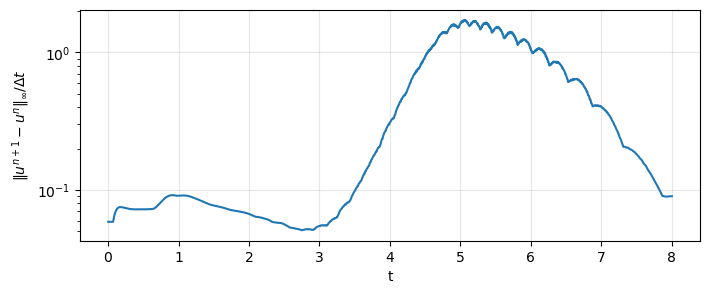

In [94]:
# residual |u^{n+1}-u^n|/dt at the stored snapshots (dimensional time)
plt.figure(figsize=(8,3))
plt.semilogy(t_snap[1:end_index+1]*T_SCALE, res[1:end_index+1])
plt.xlabel("t"); plt.ylabel(r"$\|u^{n+1}-u^n\|_\infty/\Delta t$"); plt.grid(alpha=.3)
plt.show()


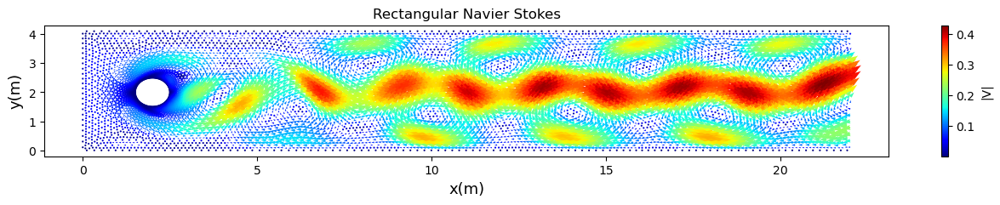

In [95]:
k = -15#end_index 
base = 00
vel = np.sqrt(u_snap[base:,k]**2 + v_snap[base:,k]**2)

plt.figure(figsize=(16,2))

q = plt.quiver(
    nodes_u[base:,0],
    nodes_u[base:,1],
    u_cur,#u_snap[base:,k],
    v_cur,#v_snap[base:,k],
    vel,
    cmap='jet'#,scale = 40
)

plt.colorbar(q, label='|V|')
plt.title("Rectangular Navier Stokes")
plt.xlabel("x(m)", fontsize = 13)
plt.xscale("linear")
plt.ylabel("y(m)",fontsize = 13)
#plt.axis('equal')
plt.show()


In [96]:
p_UP = W_UP@p_

In [97]:
#Force Coefficients
nx_test = (nodes_u[boundary_obstacle, 0] - xc) / R
ny_test = (nodes_u[boundary_obstacle, 1] - yc) / R
Dx_b_test, Dy_b_test = boundary_derivative_rows(boundary_obstacle,nodes_u, interior_nd, BND_STENCIL)

mu = 0.01
kz = -120
sigma_nn = np.zeros((boundary_obstacle.shape[0],2))
sigma_nn[:,0] = (mu*((Dx_b_test@(u_snap[:,kz]))*nx_test + (Dy_b_test@(u_snap[:,kz]))*ny_test ) - p_UP*nx_test)
sigma_nn[:,1] = mu*((Dx_b_test@(v_snap[:,kz]))*nx_test + (Dy_b_test@(v_snap[:,kz]))*ny_test ) - p_UP*ny_test

In [98]:
theta = np.arctan2(ny_test, nx_test)          # angular position of each boundary node
order = np.argsort(theta)                     # sort nodes around the circle
theta_sorted = theta[order]

# periodic wraparound so the rule closes on itself
theta_ext = np.concatenate(([theta_sorted[-1] - 2*np.pi], theta_sorted, [theta_sorted[0] + 2*np.pi]))
dtheta = (theta_ext[2:] - theta_ext[:-2]) / 2   # each point's share of the arc, in angle

ds_sorted = R * dtheta                          # convert angle-weight to arc-length weight
ds = np.zeros_like(ds_sorted)
ds[order] = ds_sorted                           # unsort back to your original node ordering

F_x = np.sum(sigma_nn[:,0] * ds)
F_y = np.sum(sigma_nn[:,1] * ds)

In [99]:
cd = 2*F_x
cl = 2*F_y
cl

np.float64(0.013301451537420756)

In [100]:
kz = -20

In [101]:
nx_test = (nodes_u[boundary_obstacle, 0] - xc) / R
ny_test = (nodes_u[boundary_obstacle, 1] - yc) / R
Dx_b_test, Dy_b_test = boundary_derivative_rows(boundary_obstacle, nodes_u, interior_nd, BND_STENCIL)
mu = 0.01
sigma_nn = np.zeros((boundary_obstacle.shape[0], 2))
sigma_nn[:,0] = mu*((Dx_b_test@u_snap[:,kz])*nx_test + (Dy_b_test@u_snap[:,kz])*ny_test) - p_UP*nx_test
sigma_nn[:,1] = mu*((Dx_b_test@v_snap[:,kz])*nx_test + (Dy_b_test@v_snap[:,kz])*ny_test) - p_UP*ny_test

theta = np.arctan2(ny_test, nx_test)
order = np.argsort(theta)
theta_sorted = theta[order]
theta_ext = np.concatenate(([theta_sorted[-1] - 2*np.pi], theta_sorted, [theta_sorted[0] + 2*np.pi]))
dtheta = (theta_ext[2:] - theta_ext[:-2]) / 2
ds_sorted = R * dtheta
ds = np.zeros_like(ds_sorted)
ds[order] = ds_sorted

F_x = np.sum(sigma_nn[:,0] * ds)
F_y = np.sum(sigma_nn[:,1] * ds)

rho  = 1.0      # DFG benchmark reference density
Ubar = 1.0      # mean inlet velocity for the Re=100 case
D    = 2*R      # cylinder diameter

Cd = 2*F_x/(rho*Ubar**2*D)
Cl = 2*F_y/(rho*Ubar**2*D)


## DFG 2D-3 results

Maxima are located on the discrete samples and then refined with a 3-point parabolic fit (otherwise the time of the maximum is only known to within ±k).
Featflow reports $\Delta p(8)$ as positive and John (2004) as negative, so it is compared in absolute value.

In [102]:
def peak(t, f):
    """Discrete maximum refined with a parabola through the 3 samples around it."""
    j = int(np.argmax(f))
    if 0 < j < len(f)-1:
        fm, f0, fp = f[j-1], f[j], f[j+1]
        den = fm - 2*f0 + fp
        if den != 0:
            delta = 0.5*(fm - fp)/den
            return t[j] + delta*(t[j+1]-t[j]), f0 - 0.25*(fm - fp)*delta
    return t[j], f[j]

t_cd, cd_max = peak(t_dim, Cd_array)
t_cl, cl_max = peak(t_dim, Cl_array)
dp8 = dp_array[-1]          # last sample = t_dim = 8 (if the run finished)

mine = dict(t_cd=t_cd, cd=cd_max, t_cl=t_cl, cl=cl_max, dp8=dp8)
labels = {"t_cd": "t(Cd max)", "cd": "Cd max", "t_cl": "t(Cl max)", "cl": "Cl max", "dp8": "dp(t=8)"}

print(f"final time computed: t = {t_dim[-1]:.6f}  (should be 8)")
print(f"{'quantity':<10}{'this run':>14}{'Featflow L6':>14}{'err %':>9}{'John 2004':>14}{'err %':>9}")
for key, name in labels.items():
    qq, b, c = mine[key], REF_FEATFLOW_L6[key], REF_JOHN_2004[key]
    if key == "dp8":
        ea, eb = abs(abs(qq)-abs(b))/abs(b)*100, abs(abs(qq)-abs(c))/abs(c)*100
    else:
        ea, eb = abs(qq-b)/abs(b)*100, abs(qq-c)/abs(c)*100
    print(f"{name:<10}{qq:>14.6f}{b:>14.6f}{ea:>9.3f}{c:>14.6f}{eb:>9.3f}")

print(f"\nDiscrete-sample values (no parabolic fit): "
      f"Cd max = {Cd_array.max():.6f} at t = {t_dim[np.argmax(Cd_array)]:.7f},  "
      f"Cl max = {Cl_array.max():.6f} at t = {t_dim[np.argmax(Cl_array)]:.7f}")


final time computed: t = 8.000000  (should be 8)
quantity        this run   Featflow L6    err %     John 2004    err %
t(Cd max)       3.942965      3.936562    0.163      3.936250    0.171
Cd max          2.978308      2.943764    1.173      2.950922    0.928
t(Cl max)       5.697554      5.692812    0.083      5.693125    0.078
Cl max          0.400417      0.477488   16.141      0.477950   16.222
dp(t=8)        -0.090751      0.111541   18.639     -0.111600   18.682

Discrete-sample values (no parabolic fit): Cd max = 2.978308 at t = 3.9428125,  Cl max = 0.400417 at t = 5.6975000


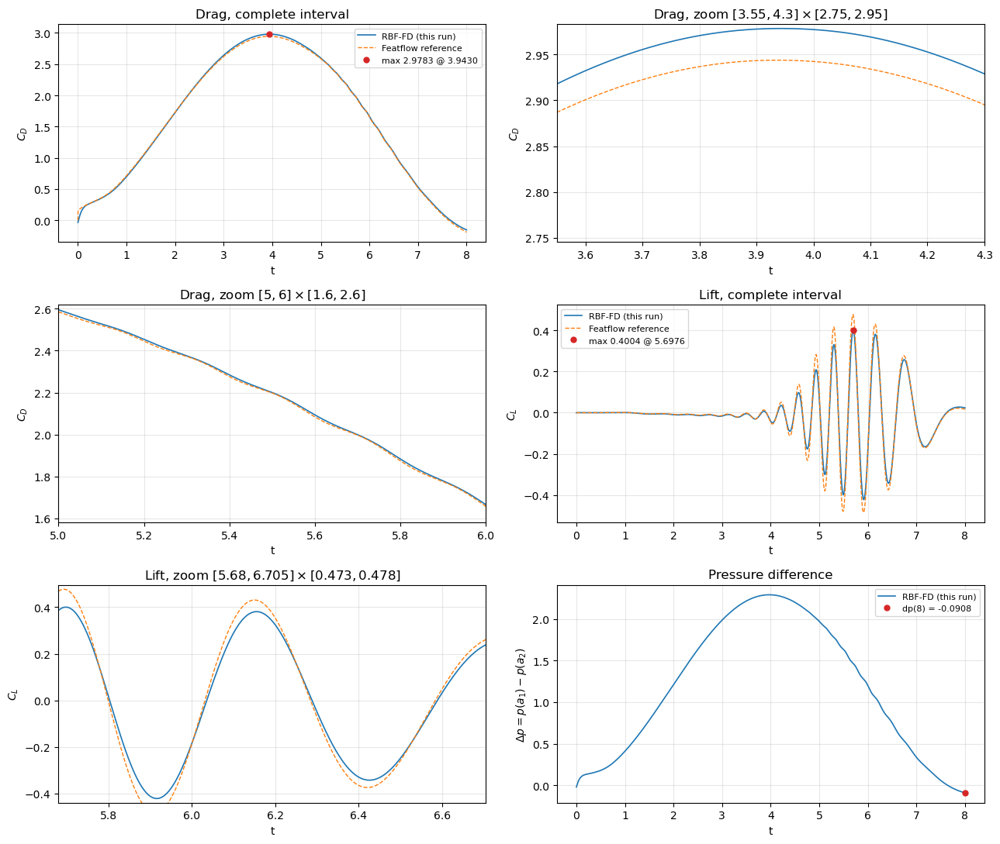

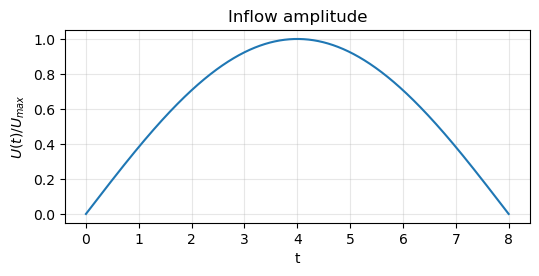

In [103]:
#Graphic results
import os
REF_FILES = {
    "cd": ("bdforces_lv6", 1, 3),   # (file, time column, value column)
    "cl": ("bdforces_lv6", 1, 4),
}

def load_ref(key):
    if key not in REF_FILES: return None
    fname, ct, cv = REF_FILES[key]
    if not os.path.exists(fname):
        print("reference file not found:", fname); return None
    d = np.loadtxt(fname, comments="#")
    return d[:, ct], d[:, cv]

def zoom(ax, t, f, xlim, ylim):
    """Website zoom window, enlarged if needed so this run's curve stays visible."""
    m = (t >= xlim[0]) & (t <= xlim[1])
    lo, hi = ylim
    if m.any():
        lo, hi = min(lo, f[m].min()), max(hi, f[m].max())
        pad = 0.02*(hi - lo)
        lo, hi = lo - pad, hi + pad
    ax.set_xlim(*xlim); ax.set_ylim(lo, hi)

def panel(ax, key, f, ylab, title, xlim=None, ylim=None):
    ax.plot(t_dim, f, lw=1.2, label="RBF-FD (this run)")
    ref = load_ref(key)
    if ref is not None:
        ax.plot(*ref, "--", lw=1, label="Featflow reference")
    if xlim is not None:
        zoom(ax, t_dim, f, xlim, ylim)
    ax.set_xlabel("t"); ax.set_ylabel(ylab); ax.set_title(title); ax.grid(alpha=.3)

fig, axs = plt.subplots(3, 2, figsize=(13, 11))
panel(axs[0,0], "cd", Cd_array, r"$C_D$", "Drag, complete interval")
axs[0,0].plot(t_cd, cd_max, "o", ms=5, color="C3", label=f"max {cd_max:.4f} @ {t_cd:.4f}")
axs[0,0].legend(fontsize=8)
panel(axs[0,1], "cd", Cd_array, r"$C_D$", r"Drag, zoom $[3.55,4.3]\times[2.75,2.95]$", (3.55, 4.3), (2.75, 2.95))
panel(axs[1,0], "cd", Cd_array, r"$C_D$", r"Drag, zoom $[5,6]\times[1.6,2.6]$", (5, 6), (1.6, 2.6))
panel(axs[1,1], "cl", Cl_array, r"$C_L$", "Lift, complete interval")
axs[1,1].plot(t_cl, cl_max, "o", ms=5, color="C3", label=f"max {cl_max:.4f} @ {t_cl:.4f}")
axs[1,1].legend(fontsize=8)
panel(axs[2,0], "cl", Cl_array, r"$C_L$", r"Lift, zoom $[5.68,6.705]\times[0.473,0.478]$", (5.68, 6.705), (0.473, 0.478))
panel(axs[2,1], "dp", dp_array, r"$\Delta p = p(a_1)-p(a_2)$", "Pressure difference")
axs[2,1].plot(t_dim[-1], dp_array[-1], "o", ms=5, color="C3", label=f"dp(8) = {dp_array[-1]:.4f}")
axs[2,1].legend(fontsize=8)
fig.tight_layout()
plt.show()

# inflow check: U(t)/Umax should be sin(pi t / 8)
plt.figure(figsize=(6,2.5))
plt.plot(t_dim, inflow_array[:len(t_dim)])
plt.xlabel("t"); plt.ylabel(r"$U(t)/U_{max}$"); plt.title("Inflow amplitude"); plt.grid(alpha=.3)
plt.show()


In [104]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

def uniform_density_subsample(coords, n_cells_x=90, n_cells_y=28):
    x, y = coords[:, 0], coords[:, 1]
    x_edges = np.linspace(x.min(), x.max(), n_cells_x + 1)
    y_edges = np.linspace(y.min(), y.max(), n_cells_y + 1)

    ix = np.clip(np.searchsorted(x_edges, x, side='right') - 1, 0, n_cells_x - 1)
    iy = np.clip(np.searchsorted(y_edges, y, side='right') - 1, 0, n_cells_y - 1)
    cell_id = ix * n_cells_y + iy

    xcc = 0.5 * (x_edges[ix] + x_edges[ix + 1])
    ycc = 0.5 * (y_edges[iy] + y_edges[iy + 1])
    dist_to_cell_center = (x - xcc) ** 2 + (y - ycc) ** 2

    order_ = np.argsort(dist_to_cell_center)
    _, first_idx_in_sorted = np.unique(cell_id[order_], return_index=True)
    keep = order_[first_idx_in_sorted]
    return np.sort(keep)

idx_sub = uniform_density_subsample(nodes_u, n_cells_x=90, n_cells_y=28)
print(f"quiver nodes: {nodes_u.shape[0]} total -> {idx_sub.size} plotted "
      f"({100*idx_sub.size/nodes_u.shape[0]:.1f}%)")

vel = np.sqrt(u_snap[:, :end_index+1]**2 + v_snap[:, :end_index+1]**2)
vmax_all = vel.max()
arrow_scale = vmax_all / 1.0
STRIDE = 10                       # animate every STRIDE-th stored snapshot

fig, ax = plt.subplots(figsize=(16, 3))
q = ax.quiver(nodes_u[idx_sub, 0], nodes_u[idx_sub, 1],
              u_snap[idx_sub, 0], v_snap[idx_sub, 0], vel[idx_sub, 0],
              cmap='jet', clim=(0, vmax_all), scale=arrow_scale,
              scale_units='xy', angles='xy', width=0.0025)
cbar = fig.colorbar(q, ax=ax, label='|V|')
ax.set_xlabel("x", fontsize=13); ax.set_ylabel("y", fontsize=13)
ax.set_aspect('equal')
ax.set_xlim(nodes_u[:, 0].min(), nodes_u[:, 0].max())
ax.set_ylim(nodes_u[:, 1].min(), nodes_u[:, 1].max())

def update(k):
    k = STRIDE * k
    q.set_UVC(u_snap[idx_sub, k], v_snap[idx_sub, k], vel[idx_sub, k])
    ax.set_title(f"DFG 2D-3 — t = {t_snap[k]*T_SCALE:.3f}   (U/Umax = {inflow_factor(t_snap[k]):.3f})")
    return q,

anim = FuncAnimation(fig, update, frames=(end_index // STRIDE) + 1, interval=30, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())


quiver nodes: 10766 total -> 2507 plotted (23.3%)


Animation size has reached 21104634 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.
